In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn jupyter

  Using cached jupyter-1.1.1-py2.py3-none-any.whl.metadata (2.0 kB)
  Using cached notebook-7.6.3-py3-none-any.whl.metadata (10 kB)
  Using cached jupyter_console-6.6.3-py3-none-any.whl.metadata (5.8 kB)
  Using cached ipywidgets-8.1.9-py3-none-any.whl.metadata (2.4 kB)
  Using cached widgetsnbextension-4.0.16-py3-none-any.whl.metadata (1.6 kB)
  Using cached jupyterlab_widgets-3.0.17-py3-none-any.whl.metadata (20 kB)
  Using cached jupyterlab-4.6.4-py3-none-any.whl.metadata (16 kB)
Using cached jupyter-1.1.1-py2.py3-none-any.whl (2.7 kB)
Using cached ipywidgets-8.1.9-py3-none-any.whl (140 kB)
Using cached jupyterlab_widgets-3.0.17-py3-none-any.whl (217 kB)
Using cached widgetsnbextension-4.0.16-py3-none-any.whl (2.2 MB)
Using cached jupyter_console-6.6.3-py3-none-any.whl (24 kB)
Using cached notebook-7.6.3-py3-none-any.whl (5.5 MB)
Using cached jupyterlab-4.6.4-py3-none-any.whl (17.2 MB)

   ----------- ---------------------------- 2/7 [ipywidgets]
   ----------- ---------------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
df = pd.read_csv("housing.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [4]:
print("Column data types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDataset information:")
df.info()

Column data types:
longitude             float64
latitude              float64
housing_median_age    float64
total_rooms           float64
total_bedrooms        float64
population            float64
households            float64
median_income         float64
median_house_value    float64
ocean_proximity           str
dtype: object

Missing values:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_r

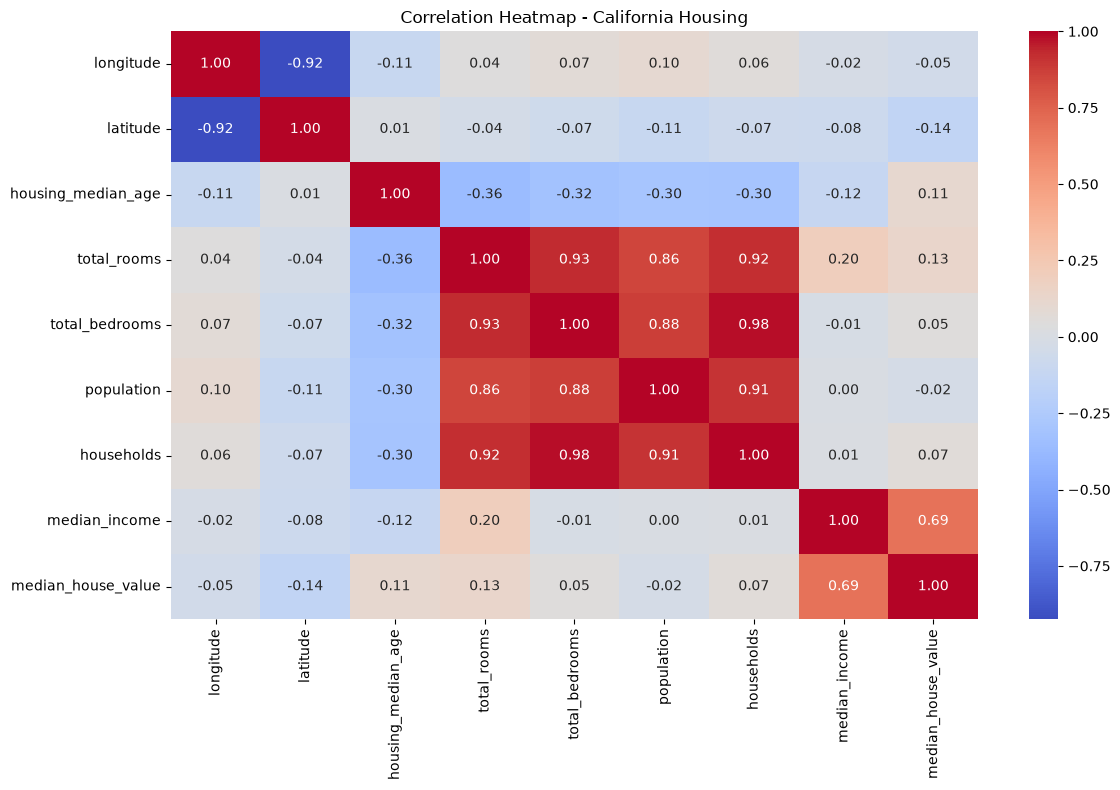

In [5]:
# Select numerical columns only
numeric_df = df.select_dtypes(include=np.number)

# Display the correlation matrix
correlation = numeric_df.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap - California Housing")
plt.tight_layout()
plt.show()

In [6]:
X = df.drop("median_house_value", axis=1)
y = df["median_house_value"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nCategorical columns:")
print(X.select_dtypes(include="object").columns.tolist())

print("\nNumerical columns:")
print(X.select_dtypes(include=np.number).columns.tolist())

Features shape: (20640, 9)
Target shape: (20640,)

Categorical columns:
['ocean_proximity']

Numerical columns:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25104\4162563322.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(X.select_dtypes(include="object").columns.tolist())


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 16512
Testing samples: 4128


In [8]:
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(include="object").columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']
Categorical features: ['ocean_proximity']


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25104\3620241715.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(include="object").columns.tolist()


In [9]:
from sklearn.preprocessing import OneHotEncoder

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [10]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("interactions", PolynomialFeatures(
        degree=2,
        interaction_only=True,
        include_bias=False
    )),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Interaction features added successfully!")

Interaction features added successfully!


In [11]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("interactions", PolynomialFeatures(
        degree=2,
        interaction_only=True,
        include_bias=False
    )),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Interaction features added successfully!")

Interaction features added successfully!


In [14]:

# Create the three regression models
ols_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", LinearRegression())
])

ridge_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", Ridge())
])

lasso_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", Lasso(max_iter=10000))
])

models = {
    "OLS": ols_model,
    "Ridge": ridge_model,
    "Lasso": lasso_model
}

# Train all three models
for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "trained successfully!")


OLS trained successfully!
Ridge trained successfully!
Lasso trained successfully!


c:\Users\LENOVO\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:840: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.212852e+13, tolerance: 2.207e+10
  model = cd_fast.enet_coordinate_descent(


In [15]:

results = []
predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "RMSE": rmse,
        "MAE": mae,
        "R² Score": r2
    })

results_df = pd.DataFrame(results).set_index("Model")

display(results_df.round(3))


,RMSE,MAE,R² Score
Model,,,
OLS,66788.296,47282.111,0.660
Ridge,67772.433,48195.817,0.649
Lasso,67675.863,48125.330,0.650


In [16]:

alpha_values = [0.01, 0.1, 1, 10, 100]

ridge_search = GridSearchCV(
    ridge_model,
    param_grid={"model__alpha": alpha_values},
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1
)

lasso_search = GridSearchCV(
    lasso_model,
    param_grid={"model__alpha": alpha_values},
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1
)

ridge_search.fit(X_train, y_train)
lasso_search.fit(X_train, y_train)

print("Best Ridge alpha:", ridge_search.best_params_)
print("Best Ridge CV RMSE:", -ridge_search.best_score_)

print("\nBest Lasso alpha:", lasso_search.best_params_)
print("Best Lasso CV RMSE:", -lasso_search.best_score_)


Best Ridge alpha: {'model__alpha': 0.01}
Best Ridge CV RMSE: 64646.2384537293

Best Lasso alpha: {'model__alpha': 0.01}
Best Lasso CV RMSE: 65502.175375965075


c:\Users\LENOVO\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:840: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.485690e+13, tolerance: 2.207e+10
  model = cd_fast.enet_coordinate_descent(


In [18]:

# Use the tuned models for the final comparison
final_models = {
    "OLS": ols_model,
    "Ridge (Tuned)": ridge_search.best_estimator_,
    "Lasso (Tuned)": lasso_search.best_estimator_
}

final_predictions = {}
final_results = []

for name, model in final_models.items():
    y_pred = model.predict(X_test)
    final_predictions[name] = y_pred

    final_results.append({
        "Model": name,
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "MAE": mean_absolute_error(y_test, y_pred),
        "R² Score": r2_score(y_test, y_pred)
    })

final_results_df = pd.DataFrame(final_results).set_index("Model")
display(final_results_df.round(3))


,RMSE,MAE,R² Score
Model,,,
OLS,66788.296,47282.111,0.660
Ridge (Tuned),66842.355,47318.801,0.659
Lasso (Tuned),67683.892,48120.866,0.650


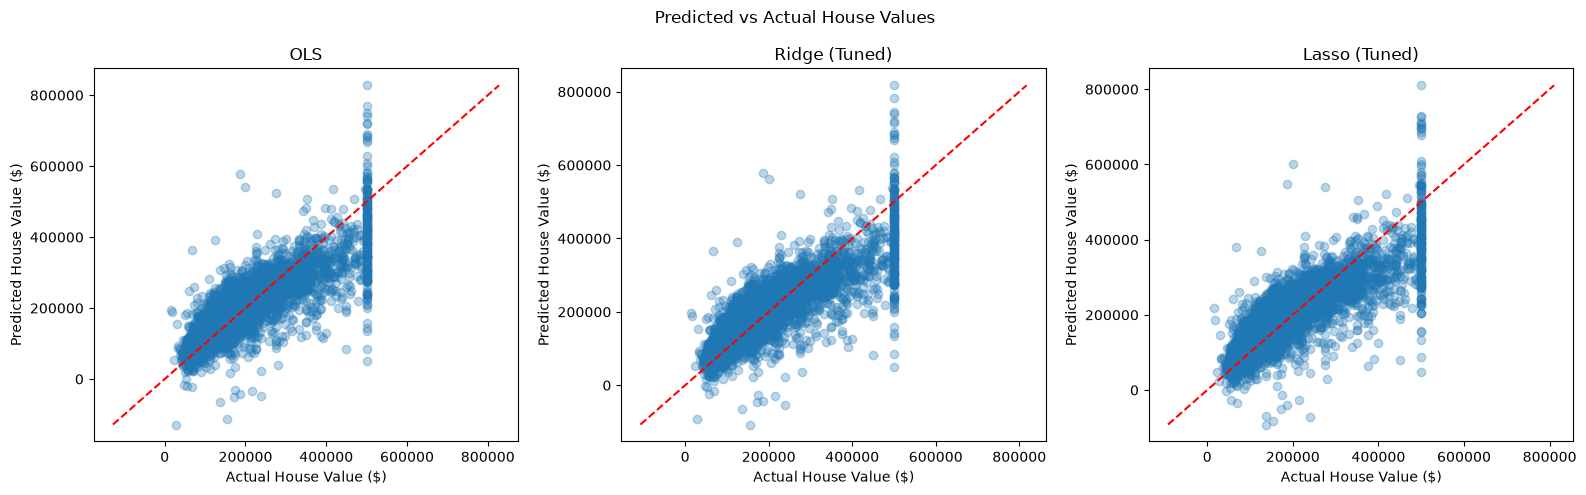

In [19]:

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (name, y_pred) in zip(axes, final_predictions.items()):
    ax.scatter(y_test, y_pred, alpha=0.3)

    low = min(y_test.min(), y_pred.min())
    high = max(y_test.max(), y_pred.max())
    ax.plot([low, high], [low, high], "r--")

    ax.set_title(name)
    ax.set_xlabel("Actual House Value ($)")
    ax.set_ylabel("Predicted House Value ($)")

plt.suptitle("Predicted vs Actual House Values")
plt.tight_layout()
plt.show()


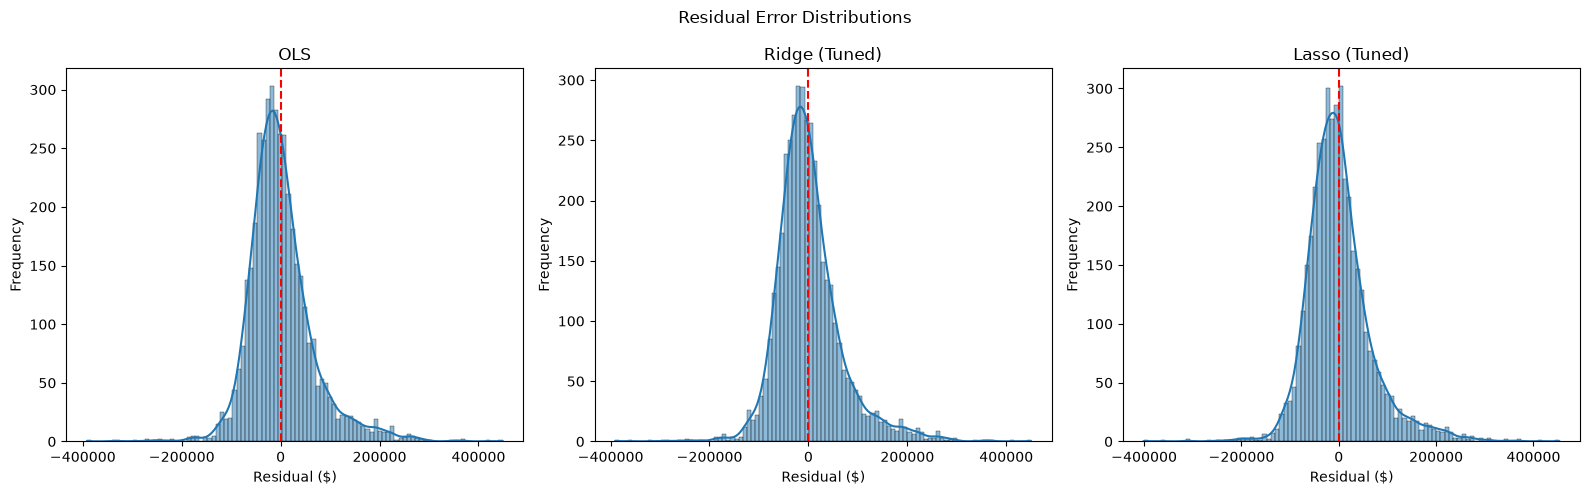

In [20]:

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (name, y_pred) in zip(axes, final_predictions.items()):
    residuals = y_test.to_numpy() - y_pred

    sns.histplot(
        residuals,
        kde=True,
        ax=ax
    )

    ax.axvline(0, color="red", linestyle="--")
    ax.set_title(name)
    ax.set_xlabel("Residual ($)")
    ax.set_ylabel("Frequency")

plt.suptitle("Residual Error Distributions")
plt.tight_layout()
plt.show()


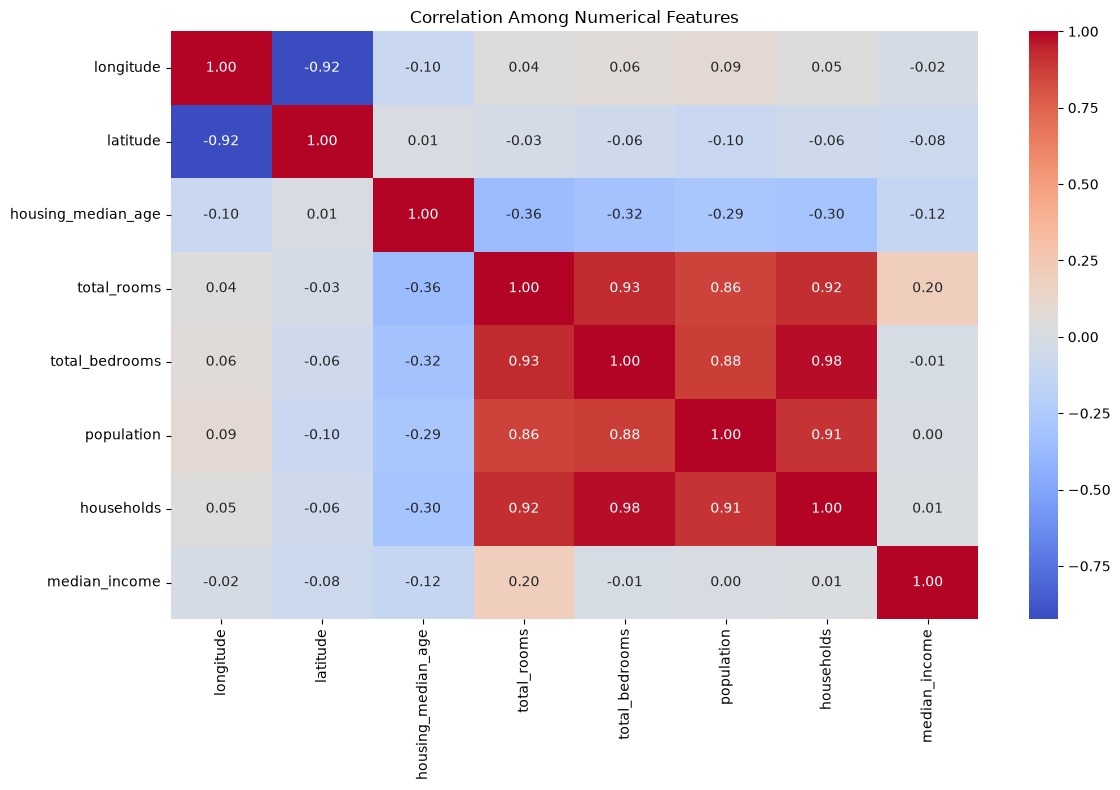

In [21]:

plt.figure(figsize=(12, 8))

sns.heatmap(
    X_train[numeric_features].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Among Numerical Features")
plt.tight_layout()
plt.show()


In [24]:
%pip install statsmodels
from statsmodels.stats.outliers_influence import variance_inflation_factor



# Impute missing values and scale numerical training features
vif_imputer = SimpleImputer(strategy="median")
vif_scaler = StandardScaler()

X_vif = vif_imputer.fit_transform(X_train[numeric_features])
X_vif = vif_scaler.fit_transform(X_vif)

# Calculate VIF for each numerical feature
vif_df = pd.DataFrame({
    "Feature": numeric_features,
    "VIF": [
        variance_inflation_factor(X_vif, i)
        for i in range(X_vif.shape[1])
    ]
})

display(vif_df.sort_values("VIF", ascending=False).round(3))



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   --- ------------------------------------ 1.0/11.3 MB 7.4 MB/s eta 0:00:02
   --------- ------------------------------ 2.6/11.3 MB 7.2 MB/s eta 0:00:02
   -------------- ------------------------- 4.2/11.3 MB 7.4 MB/s eta 0:00:01
   --------------------- ------------------ 6.0/11.3 MB 7.6 MB/s eta 0:00:01
   -------------------------- ------------- 7.6/11.3 MB 7.7 MB/s eta 0:00:01
   --------------------------------- ------ 9.4/11.3 MB 7.8 MB/s eta 0:00:01
   -------------------------------------- - 11.0/11.3 MB 7.9 MB/s eta 0:00:01
   ---------------------------------------- 11.3/11.3 MB 7.7 MB/s  0:00:01

   -------- ------------------------------- 1/5 [patsy]
   ------------------------ --------------- 3/5 [formulaic]
   ------------------------ --------------- 3/5 [formulaic]
   -------------------------------- ------- 4/5 [statsmodels]
   -------------------------------- ------- 4/5 [statsmodels]
   -----------

,Feature,VIF
4,total_bedrooms,36.307
6,households,35.825
3,total_rooms,12.822
1,latitude,8.798
0,longitude,8.682
5,population,6.345
7,median_income,1.741
2,housing_median_age,1.258


Conclusion

In this project, I developed a house-value prediction system using the California Housing dataset. I explored the data using descriptive statistics and correlation heatmaps, handled missing values, standardized numerical features, encoded categorical features, and engineered interaction features.

I trained and compared three regression models: Ordinary Least Squares (OLS), Ridge Regression, and Lasso Regression. I used GridSearchCV to tune the regularization parameter (alpha) for Ridge and Lasso. The models were evaluated using Root Mean Squared Error (RMSE), Mean Absolute Error (MAE), and R² score.

Finally, I visualized predicted versus actual house values, residual error distributions, and correlations among numerical features. This project helped me understand regression, feature engineering, regularization, model evaluation, and the importance of handling multicollinearity.

The best-performing model should be identified from the evaluation results based on the selected metrics.